In [2]:
from collections import Counter
import pandas as pd
from sklearn.cluster import KMeans
from collections import Counter
import pandas as pd
from sklearn.cluster import Birch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage1\dataset1_729×87.xlsx")
X = data.iloc[:, 3:]
print(X)
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

     band_gap     vbm    efermi   density  MagpieData mean MendeleevNumber  \
0      3.9641  1.5315  1.620862  3.963466                        62.944444   
1      5.0780  1.5258  1.570907  3.970678                        67.952381   
2      5.2118  1.2042  1.237303  3.985401                        67.904762   
3      4.0463  1.2514  5.297637  3.445198                        68.166667   
4      4.8124  1.1115  1.119990  3.694735                        71.093750   
..        ...     ...       ...       ...                              ...   
724    4.4992  4.1609  4.313224  3.797135                        73.913043   
725    4.6260  1.6168  1.740793  4.115359                        64.625000   
726    3.7912  1.2831  1.283116  4.663366                        66.350000   
727    3.2862  1.0829  1.146768  4.847039                        66.450000   
728    3.3427  1.0680  1.185559  2.994664                        69.652174   

     MagpieData minimum AtomicWeight  MagpieData range MeltingT

(729, 87)

Computing t-SNE embedding...
t-SNE embedding completed in 2.15s
Visualization saved as 'tsne_visualization.png'


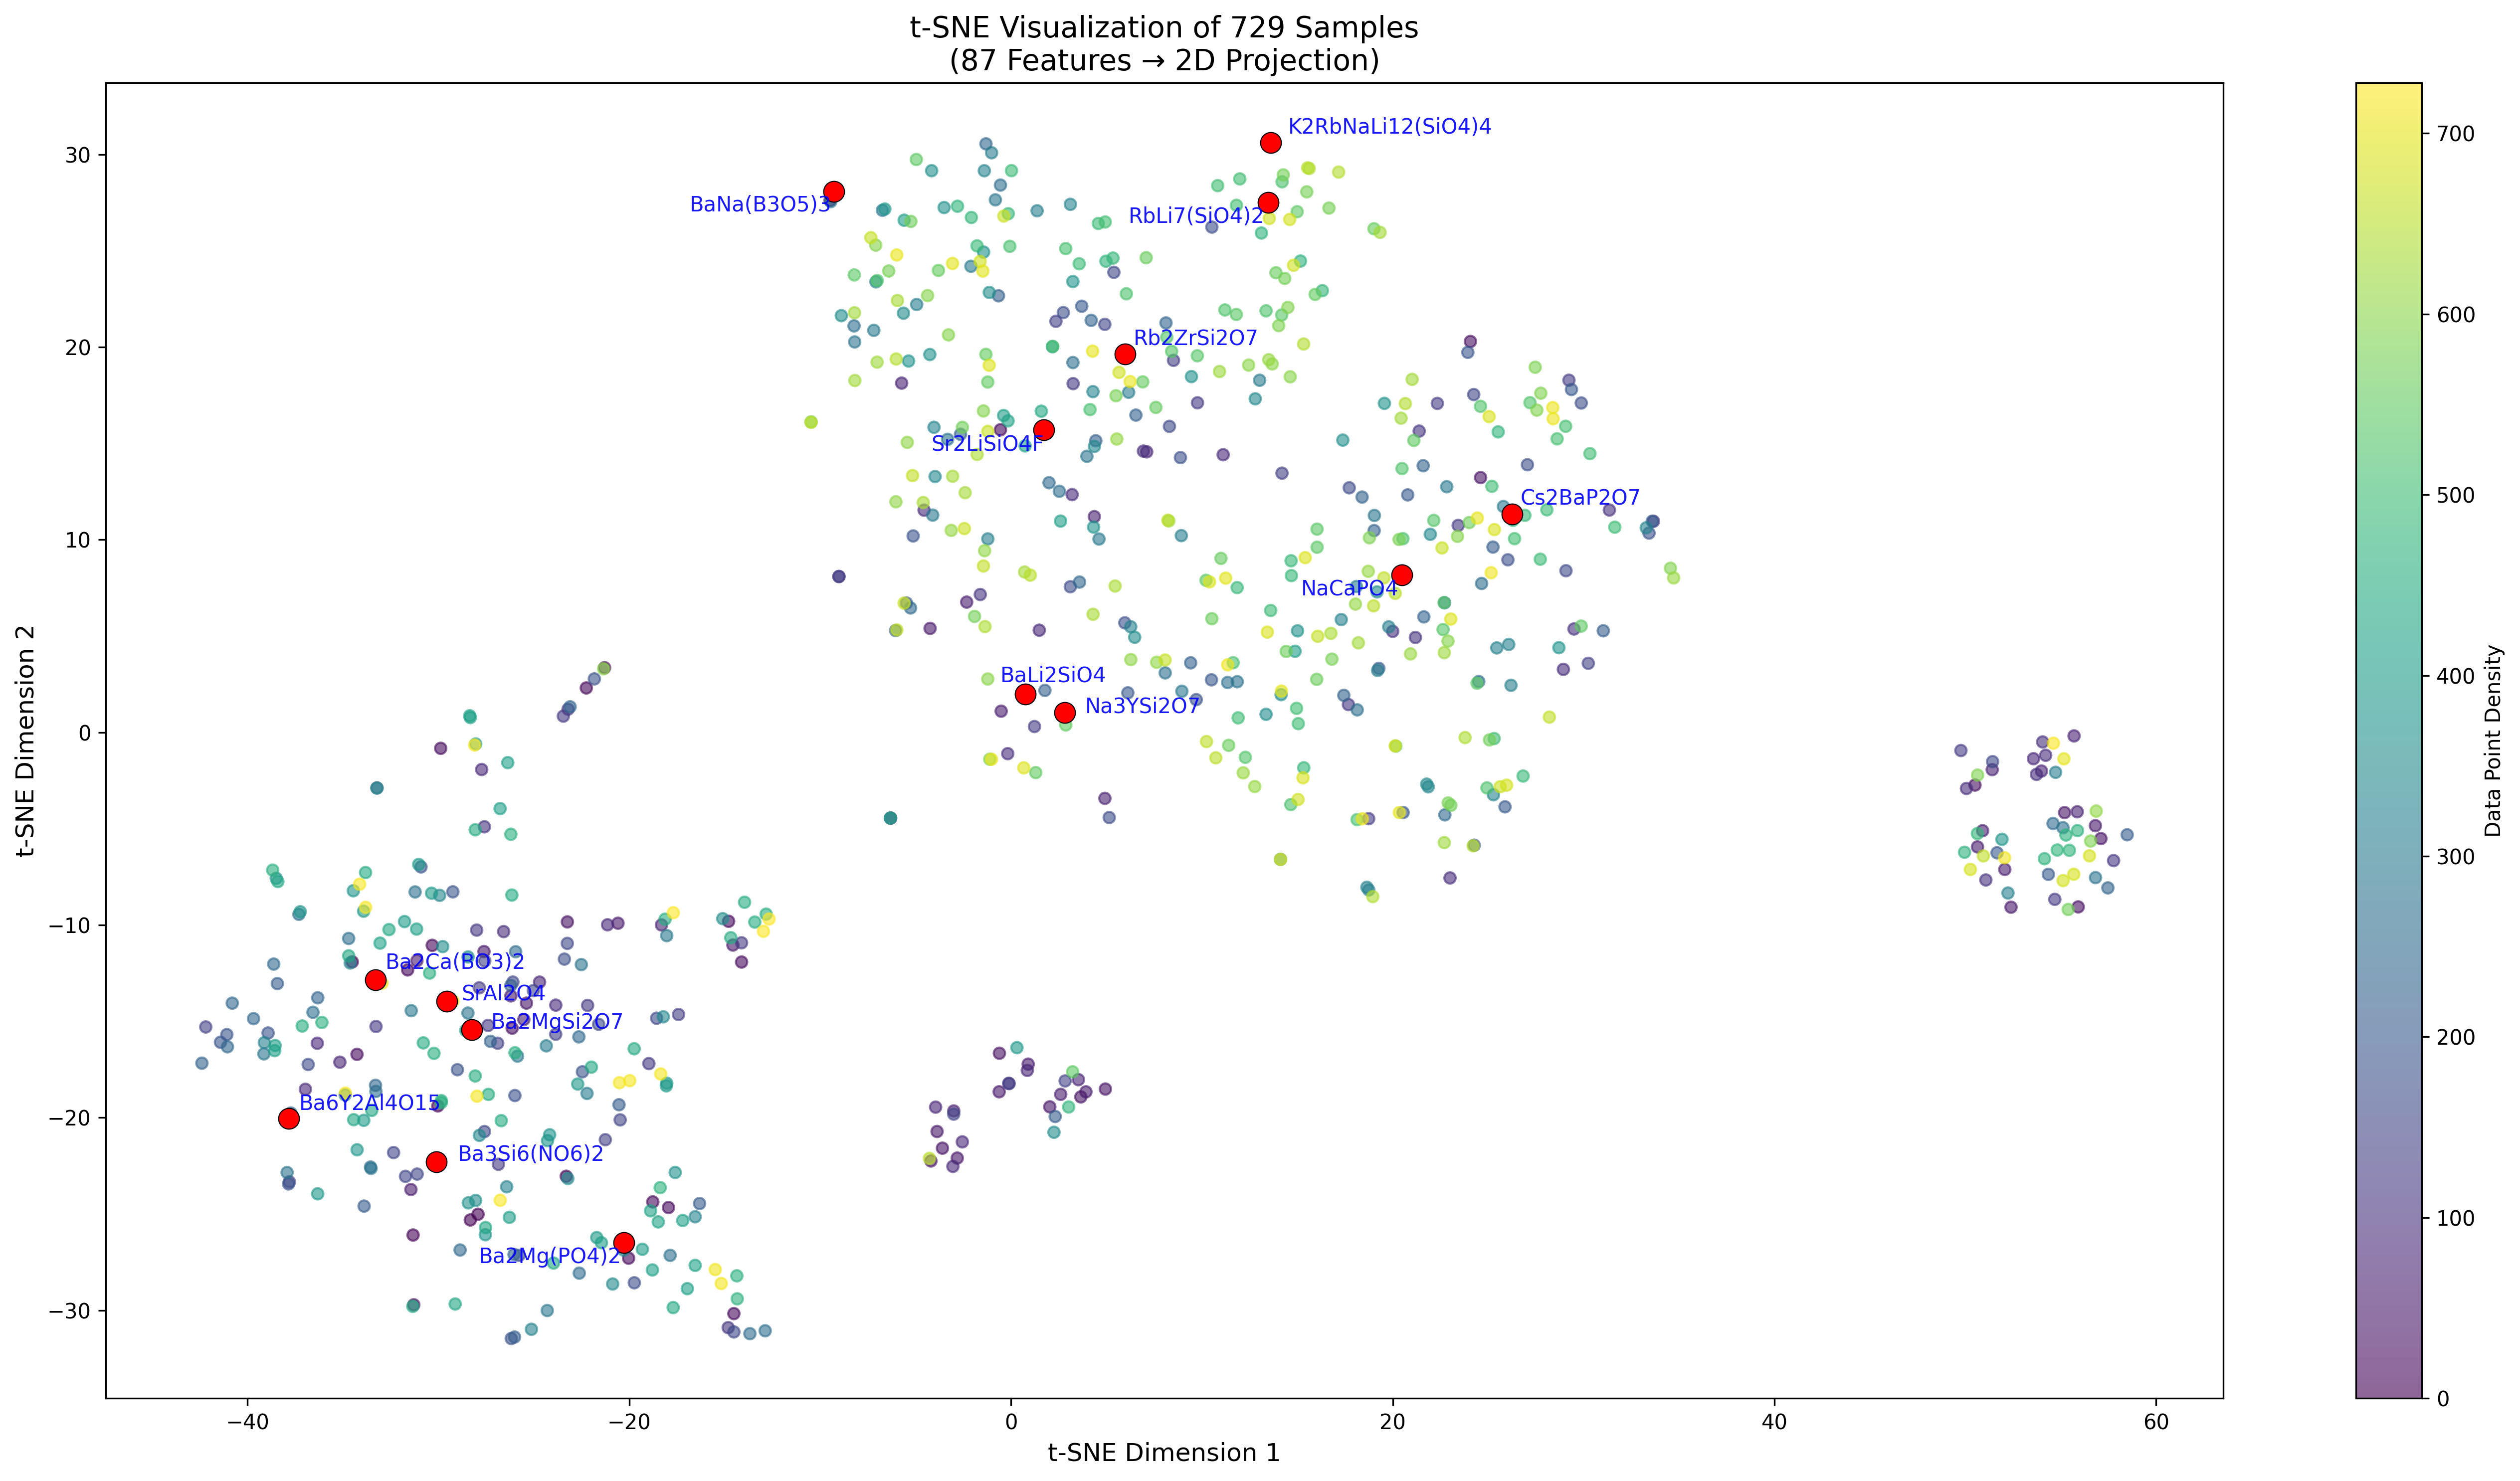

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from time import time
from adjustText import adjust_text

label_col = data.iloc[:, 2]

n_samples = X.shape[0]
n_features = X.shape[1]

print("Computing t-SNE embedding...")
tsne = TSNE(n_components=2,
            perplexity=30,
            max_iter=1000,
            random_state=42)

t0 = time()
X_tsne = tsne.fit_transform(X)
print(f"t-SNE embedding completed in {time()-t0:.2f}s")

plt.figure(figsize=(18.6, 10), dpi=300)

scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
                     c=np.arange(n_samples),
                     cmap='viridis',
                     alpha=0.6,
                     s=30)

cbar = plt.colorbar(scatter)
cbar.set_label('Data Point Density')

highlight_indices = [21,22,23,24,259,299,383,386,399,403,422,434,488,640,702]

texts = []

for idx in highlight_indices:
    if idx < len(X_tsne):

        plt.scatter(X_tsne[idx, 0], X_tsne[idx, 1],
                   c='red', s=100, edgecolors='black', linewidths=0.5,
                   zorder=3)

        text = plt.text(X_tsne[idx, 0], X_tsne[idx, 1],
                       str(label_col.iloc[idx]),
                       fontsize=10,
                       color='blue',
                       alpha=0.9,
                       ha='center', va='center',
                       zorder=4)
        texts.append(text)

if 'adjust_text' in globals() and callable(adjust_text):
    adjust_text(texts,
                only_move={'points':'y', 'texts':'xy'},

                expand_points=(1.2, 1.5),
                expand_text=(1.2, 1.5),
                force_text=(0.2, 0.5),
                force_points=(0.2, 0.5))
else:
    print("Warning: adjust_text function not available, using manual adjustment")

    for i, text in enumerate(texts):
        if i % 3 == 0:
            text.set_position((text.get_position()[0], text.get_position()[1]+0.5))
        elif i % 3 == 1:
            text.set_position((text.get_position()[0]+0.3, text.get_position()[1]-0.3))

plt.title(f't-SNE Visualization of {n_samples} Samples\n'
          f'({n_features} Features → 2D Projection)', fontsize=14)
plt.xlabel('t-SNE Dimension 1', fontsize=12)
plt.ylabel('t-SNE Dimension 2', fontsize=12)

plt.tight_layout()

plt.savefig('tsne_visualization.png', dpi=300, bbox_inches='tight')
print("Visualization saved as 'tsne_visualization.png'")

plt.show()

In [5]:
pca = PCA(n_components= 23, random_state=42)
X = pd.DataFrame(X)
new_data = pca.fit_transform(X)
print(new_data.shape)
ratios = pca.explained_variance_ratio_
components = pca.components_

components_df = pd.DataFrame(
    components,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(components.shape[0])]
)

output_file = "pca_components_1.xlsx"
components_df.to_excel(output_file, index=True)

(729, 23)


(729, 23)


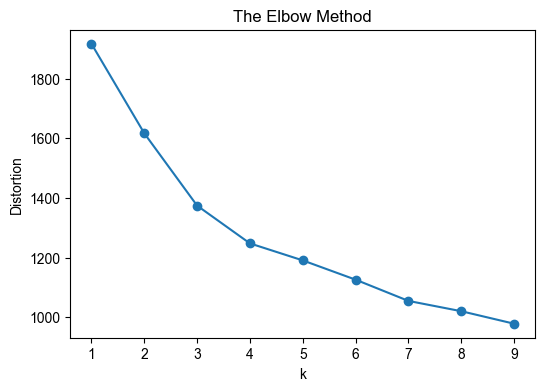

In [6]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
print(new_data.shape)
X  =new_data
distortions = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X)
    distortions.append(kmeans.inertia_)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.figure(figsize=(6, 4), dpi=100)
plt.plot(K_range, distortions, 'o-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method')
plt.show()

(729, 23)


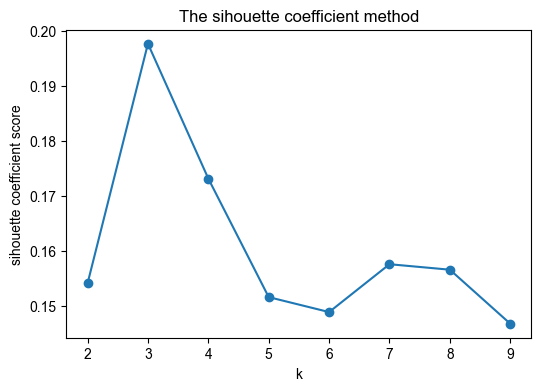

In [10]:

X  =new_data
print(X.shape)
SC = []
k_min = 2
k_max = 10
for k in range(k_min, k_max):
    kmeans_model = KMeans(n_clusters=k, random_state=10)
    kmeans_model.fit(X)
    sc_score  = silhouette_score(X, kmeans_model.labels_)
    SC.append(sc_score)

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.figure(figsize=(6, 4), dpi=100)
plt.plot(range(k_min, k_max), SC, marker='o')
plt.title('The sihouette coefficient method')
plt.xlabel('k')
plt.ylabel('sihouette coefficient score')
plt.show()

In [11]:

def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(df.at[index, 'number'])
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage1\benchmark1.xlsx"
reported_structures = extract_numbers(file_path)
print(reported_structures)

[np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(260), np.int64(300), np.int64(384), np.int64(387), np.int64(400), np.int64(404), np.int64(423), np.int64(435), np.int64(489), np.int64(641), np.int64(703)]


In [12]:
X = new_data
print(X.shape)
for i in range(3, 7):
    kmeans_plus = KMeans(n_clusters=i, init='random', random_state=42, n_init= 'auto', tol=1e-5, )
    kmeans_plus.fit(X)
    labels = kmeans_plus.labels_
    silhouette_score(X, labels)
    calinski_harabasz_score(X, labels)

    data[f'cluster_{i}'] = labels
    dict = {}

    label_1 = []
    for num  in  reported_structures:
        label = labels[num-1]
        label_1.append(label)
    print(label_1)

    for cluster in range(i):

        cluster_samples = data[data[f'cluster_{i}'] == cluster]

        total_in_cluster = len(cluster_samples)

        reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])
        dict[cluster] = (reported_in_cluster, total_in_cluster)
    for value in dict.values():
        if value[0] == 0:
            for key, value in dict.items():

                formatted_value = f"{value[0]}/{value[1]}"


(729, 23)
[np.int32(2), np.int32(2), np.int32(2), np.int32(1), np.int32(2), np.int32(1), np.int32(1), np.int32(1), np.int32(1), np.int32(2), np.int32(2), np.int32(1), np.int32(2), np.int32(2), np.int32(2)]
[np.int32(0), np.int32(0), np.int32(0), np.int32(1), np.int32(0), np.int32(1), np.int32(1), np.int32(1), np.int32(1), np.int32(0), np.int32(0), np.int32(1), np.int32(2), np.int32(2), np.int32(0)]
[np.int32(3), np.int32(3), np.int32(3), np.int32(0), np.int32(3), np.int32(0), np.int32(0), np.int32(0), np.int32(0), np.int32(3), np.int32(3), np.int32(0), np.int32(4), np.int32(4), np.int32(3)]
[np.int32(5), np.int32(4), np.int32(5), np.int32(3), np.int32(5), np.int32(3), np.int32(3), np.int32(3), np.int32(3), np.int32(4), np.int32(5), np.int32(3), np.int32(1), np.int32(5), np.int32(5)]


In [ ]:
print(X.shape)

(729, 23)


In [13]:
from collections import Counter
import pandas as pd
from sklearn.cluster import KMeans
from collections import Counter
import pandas as pd
from sklearn.cluster import Birch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage1\dataset1_729×87.xlsx")
X = data.iloc[:, 3:]
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

(729, 87)

In [14]:

def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(int(df.at[index, 'number']))
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage1\benchmark1.xlsx"
reported_structures = extract_numbers(file_path)
print(reported_structures)

for j in range(30, 100, 5):
    j = j/100

    pca = PCA(n_components= j)
    pca_data = pca.fit_transform(X)
    num_pca = pca_data.shape[1]

    for i in range(3, 7):
        kmeans_plus = KMeans(n_clusters=i, init='random', random_state=42, n_init= 'auto', tol=1e-5, )
        kmeans_plus.fit(pca_data)
        labels = kmeans_plus.labels_

        data[f'cluster_{i}'] = labels
        dict = {}

        label_1 = []
        for num  in  reported_structures:
            label = labels[num-1]
            label_1.append(int(label))
        print(label_1)

        for cluster in range(i):

            cluster_samples = data[data[f'cluster_{i}'] == cluster]

            total_in_cluster = len(cluster_samples)

            reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])
            dict[cluster] = (reported_in_cluster, total_in_cluster)
        for value in dict.values():
            if value[0] == 0:
                for key, value in dict.items():

                    formatted_value = f"{value[0]}/{value[1]}"


[22, 23, 24, 25, 260, 300, 384, 387, 400, 404, 423, 435, 489, 641, 703]
[2, 2, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2]
[2, 2, 2, 3, 2, 3, 3, 3, 1, 2, 2, 3, 2, 2, 2]
[2, 1, 2, 3, 2, 3, 3, 3, 4, 1, 2, 3, 2, 2, 2]
[4, 2, 2, 5, 1, 5, 5, 5, 0, 2, 1, 5, 4, 4, 4]
[2, 2, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2]
[1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 3, 3, 1]
[2, 2, 2, 3, 2, 3, 3, 3, 3, 2, 2, 3, 0, 0, 2]
[0, 0, 0, 2, 0, 2, 2, 1, 3, 0, 0, 2, 5, 5, 0]
[2, 2, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2]
[1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 3, 3, 1]
[2, 2, 2, 3, 2, 3, 3, 3, 3, 2, 2, 3, 0, 0, 2]
[0, 0, 0, 2, 0, 2, 2, 1, 3, 0, 0, 2, 5, 5, 0]
[2, 2, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2]
[0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 2, 2, 0]
[4, 4, 4, 3, 4, 3, 3, 3, 3, 4, 4, 3, 0, 0, 4]
[3, 5, 3, 4, 3, 4, 4, 4, 2, 5, 3, 4, 1, 3, 5]
[2, 2, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2]
[0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 2, 2, 0]
[4, 4, 4, 3, 4, 3, 3, 3, 3, 4, 4, 3, 0, 0, 4]
[3, 5, 3, 4, 3, 4, 4, 4, 2, 5, 3, 4, 1, 3, 5]
[0, 0, 0

In [15]:
pca = PCA(n_components= 0.55, random_state=42)
new_data = pca.fit_transform(X)
print(new_data.shape)
ratios = pca.explained_variance_ratio_
components = pca.components_
X = pd.DataFrame(X)

components_df = pd.DataFrame(
    components,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(components.shape[0])]
)

output_file = "pca_components.xlsx"
components_df.to_excel(output_file, index=True)

i = 6
kmeans_plus = KMeans(n_clusters=i, init='random', random_state=42, n_init= 'auto', tol=1e-5)
kmeans_plus.fit(new_data)
labels = kmeans_plus.labels_
print(f"Silhouette score: {silhouette_score(new_data, labels):.2f}")
print(f"Calinski-Harabasz score: {calinski_harabasz_score(new_data, labels):.2f}")
df = pd.DataFrame(labels)
df.to_excel("kmeans_result.xlsx")

data[f'cluster_{i}'] = labels

for cluster in range(i):

    cluster_samples = data[data[f'cluster_{i}'] == cluster]

    total_in_cluster = len(cluster_samples)
    print(total_in_cluster)

    reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])


(729, 5)
Silhouette score: 0.28
Calinski-Harabasz score: 240.16
63
124
159
56
124
203


In [16]:
import pandas as pd
from sklearn.decomposition import PCA
from openpyxl.styles import Font
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl import Workbook

wb = Workbook()
ws = wb.active

for r in dataframe_to_rows(components_df, index=True, header=True):
    ws.append(r)

red_bold_font = Font(color="FF0000", bold=True)

for row in range(2, ws.max_row + 1):

    values = [ws.cell(row=row, column=col).value for col in range(2, ws.max_column + 1)]

    values = [0 if v is None else v for v in values]

    abs_values = [abs(v) for v in values]
    top_10_indices = sorted(range(len(abs_values)), key=lambda i: abs_values[i], reverse=True)[:10]

    for idx in top_10_indices:
        ws.cell(row=row, column=idx + 2).font = red_bold_font

output_file = "pca_components_highlighted.xlsx"
wb.save(output_file)
